# Results

In [23]:
import pandas as pd
import glob
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [17]:
files = glob.glob("../results/*_metrics.csv")
print(files)

['../results/baseline_metrics.csv', '../results/roberta_seed42_metrics.csv', '../results/bertweet_seed42_metrics.csv', '../results/modernbert_seed44_metrics.csv', '../results/roberta_seed44_metrics.csv', '../results/bertweet_seed44_metrics.csv', '../results/modernbert_seed42_metrics.csv', '../results/bertweet_seed43_metrics.csv', '../results/roberta_seed43_metrics.csv', '../results/modernbert_seed43_metrics.csv']


In [18]:
tables = []
for f in files:
    table = pd.read_csv(f)
    tables.append(table)

all_results = pd.concat(tables, ignore_index=True)

print(all_results)

         model       split  f1_sarcastic  f1_macro  precision    recall  seed
0     baseline  validation      0.336996  0.549887   0.319444  0.356589   NaN
1     baseline        test      0.280179  0.526656   0.199575  0.470000   NaN
2      roberta  validation      0.530612  0.672314   0.472727  0.604651  42.0
3      roberta        test      0.357542  0.568406   0.248062  0.640000  42.0
4     bertweet  validation      0.619529  0.733310   0.547619  0.713178  42.0
5     bertweet        test      0.450832  0.640563   0.323210  0.745000  42.0
6   modernbert  validation      0.452830  0.605245   0.380952  0.558140  44.0
7   modernbert        test      0.339853  0.533701   0.224919  0.695000  44.0
8      roberta  validation      0.465409  0.614320   0.391534  0.573643  44.0
9      roberta        test      0.324393  0.531061   0.217839  0.635000  44.0
10    bertweet  validation      0.619048  0.748299   0.634146  0.604651  44.0
11    bertweet        test      0.473779  0.672137   0.371105  0

In [19]:
test_results = all_results[all_results["split"] == "test"]
print(test_results)

         model split  f1_sarcastic  f1_macro  precision  recall  seed
1     baseline  test      0.280179  0.526656   0.199575   0.470   NaN
3      roberta  test      0.357542  0.568406   0.248062   0.640  42.0
5     bertweet  test      0.450832  0.640563   0.323210   0.745  42.0
7   modernbert  test      0.339853  0.533701   0.224919   0.695  44.0
9      roberta  test      0.324393  0.531061   0.217839   0.635  44.0
11    bertweet  test      0.473779  0.672137   0.371105   0.655  44.0
13  modernbert  test      0.254942  0.217494   0.147593   0.935  42.0
15    bertweet  test      0.475138  0.674432   0.376093   0.645  43.0
17     roberta  test      0.372712  0.600635   0.279302   0.560  43.0
19  modernbert  test      0.279938  0.532644   0.203160   0.450  43.0


In [20]:
val_results = all_results[all_results["split"] == "validation"]
print(val_results)

         model       split  f1_sarcastic  f1_macro  precision    recall  seed
0     baseline  validation      0.336996  0.549887   0.319444  0.356589   NaN
2      roberta  validation      0.530612  0.672314   0.472727  0.604651  42.0
4     bertweet  validation      0.619529  0.733310   0.547619  0.713178  42.0
6   modernbert  validation      0.452830  0.605245   0.380952  0.558140  44.0
8      roberta  validation      0.465409  0.614320   0.391534  0.573643  44.0
10    bertweet  validation      0.619048  0.748299   0.634146  0.604651  44.0
12  modernbert  validation      0.436823  0.394760   0.284706  0.937984  42.0
14    bertweet  validation      0.609375  0.740585   0.614173  0.604651  43.0
16     roberta  validation      0.456432  0.645826   0.491071  0.426357  43.0
18  modernbert  validation      0.404580  0.601515   0.398496  0.410853  43.0


In [28]:
metric_columns = ["f1_sarcastic", "f1_macro", "precision", "recall"]

test_summary = test_results.groupby("model")[metric_columns].agg(["count", "mean", "std"])
print(test_summary.round(3))

val_summary = val_results.groupby("model")[metric_columns].agg(["count", "mean", "std"])
print(val_summary.round(3))

           f1_sarcastic               f1_macro               precision         \
                  count   mean    std    count   mean    std     count   mean   
model                                                                           
baseline              1  0.280    NaN        1  0.527    NaN         1  0.200   
bertweet              3  0.467  0.014        3  0.662  0.019         3  0.357   
modernbert            3  0.292  0.044        3  0.428  0.182         3  0.192   
roberta               3  0.352  0.025        3  0.567  0.035         3  0.248   

                  recall                
              std  count   mean    std  
model                                   
baseline      NaN      1  0.470    NaN  
bertweet    0.029      3  0.682  0.055  
modernbert  0.040      3  0.693  0.243  
roberta     0.031      3  0.612  0.045  
           f1_sarcastic               f1_macro               precision         \
                  count   mean    std    count   mean    std    

To compare with the case where one guess that all tweets are sarcastic, the F1-score will be around 0.25.

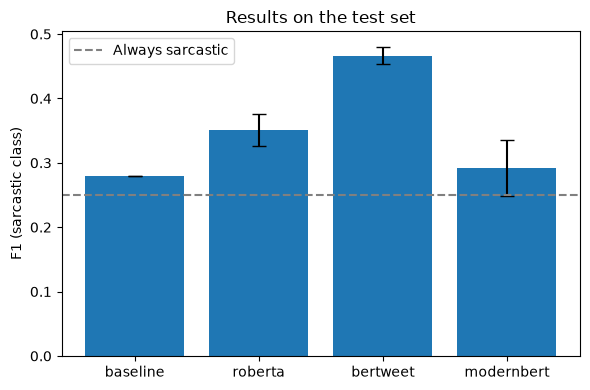

In [27]:
models = ["baseline", "roberta", "bertweet", "modernbert"]

means = test_summary.loc[models, ("f1_sarcastic", "mean")]
stds = test_summary.loc[models, ("f1_sarcastic", "std")].fillna(0)
# reference = test_summary.loc["always_sarcastic", ("f1_sarcastic", "mean")]
reference = 0.25

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(models, means, yerr=stds, capsize=5)
ax.axhline(reference, linestyle="--", color="gray", label="Always sarcastic")
ax.set_ylabel("F1 (sarcastic class)")
ax.set_title("Results on the test set")
ax.legend()
plt.tight_layout()
plt.savefig("../plots/f1_by_model.png", dpi=200)
plt.show()

## Collected results
| **Model** | **Validation F1** | **Test F1**|
|---|---|---|
| Always sarcastic | ~0.40 | ~0.25 |
| Baseline | 0.337 | 0.280 |
| RoBERTa | 0.484±0.04 | 0.352±0.025 |
| BERTweet | 0.616±0.006 | 0.467±0.014 |
| ModernBERT | 0.431±0.02 | 0.292±0.044 |

## Observations
1. **BERTweet is clearly the best one.** It has a F1-score of 0.467 on the testset. It also has the least variance between the seeds, with 0.014. 
2. **RoBERTa is better than the baseline.** This shows that a transformer that understand the connections in a sentence is better than a model that only looks at single words.
3. **ModernBERT performs the worst of the transformers.** It is only a bit better than the baseline. It also has the biggest variance between the seeds (0.044). With seed 42 it basicly learned nothing. 
4. For sarcasm in tweets it looks like a model trained on tweets is better than a newer model. The newest model actually performs the worst of the three that is trained on English text.
5. **All models performs worse on the test set than the validation set.** A possible explaination to this is that the test set has a lower share of sarcastic tweets than the training/validation set. All models has low precision and high recall on the test set, so they over predict sarcasm. 